In [1]:
# 5_2_2_predict_rasters.ipynb
#
# Uses the aggregated RF regressor (trained in 5_1) and the full prediction
# dataframe (built in 5_2_1) to produce one GeoTIFF per calendar month.
#
# WORKFLOW
# 1. Load config, model, and spatial template
# 2. Iterate over months in the period range
# 3. Per month: load rows from parquet, predict, reconstruct DataArray
# 4. Align DataArray to template extent via reproject_match
# 5. Save as float32 GeoTIFF

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
from tqdm import tqdm

# ── Date range ──────────────────────────────────────────────────────────────
START_YEAR,  START_MONTH = 2001, 1
END_YEAR,    END_MONTH   = 2005, 12

# ── Paths ───────────────────────────────────────────────────────────────────
PARQUET_PATH  = r"..\Data\Processed\PredictedRasters\final_df.parquet"
MODEL_PATH    = r"..\Data\Processed\RegressionModel\Saved_regressors\Aggregated_rf_regressor.pkl"
TEMPLATE_PATH = r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif"
OUT_DIR       = r"..\Data\Processed\PredictedRasters\Final_rasters"

os.makedirs(OUT_DIR, exist_ok=True)

# ── Predictor feature list (must match training order in 5_1) ───────────────
PREDICTOR_FEATURES = ['y', 'x', 
        'era5l_monthly_sum', 'chirps_monthly_sum', 'har_monthly_sum', 
        'persiann_monthly_sum', 'mswep_monthly_sum', 
        'chirps_wet_day_count', 'chirps_monthly_std',
        'evi_monthly_mean', 'lst_d_monthly_mean', 'lst_d_missing_fraction',
        'lst_n_monthly_mean', 'lst_n_missing_fraction', 'lst_diff_monthly_mean',
        'cluster', 'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 
        'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
        'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 'month_sin', 'month_cos']

print(f"Output directory : {OUT_DIR}")
print(f"Predictor features : {len(PREDICTOR_FEATURES)}")

Output directory : ..\Data\Processed\PredictedRasters\Final_rasters
Predictor features : 30


In [3]:
# ── Load model and spatial template ─────────────────────────────────────────

print("Loading RF model ...")
model = joblib.load(MODEL_PATH)
print(f"  Model loaded: {type(model).__name__}")

print("Loading spatial template ...")
template = rxr.open_rasterio(TEMPLATE_PATH, masked=True)
print(f"  Template CRS       : {template.rio.crs}")
print(f"  Template shape     : {template.squeeze().shape}   (rows x cols)")
print(f"  Template transform : {template.rio.transform()}")

Loading RF model ...
  Model loaded: Pipeline
Loading spatial template ...
  Template CRS       : EPSG:4326
  Template shape     : (493, 983)   (rows x cols)
  Template transform : | 0.01, 0.00, 79.65|
| 0.00,-0.01, 30.61|
| 0.00, 0.00, 1.00|


In [4]:
# ── Main prediction loop ─────────────────────────────────────────────────────
#
# For each month:
#   1. Skip if the output raster already exists (safe to re-run)
#   2. Read only that month's rows from parquet (memory-efficient)
#   3. Predict with the RF model (using .values to suppress feature-name warning)
#   4. Pivot predictions back to a 2-D DataArray indexed by (y, x)
#   5. Write CRS / nodata / transform, then align to full template extent
#   6. Save as float32 GeoTIFF

month_range = pd.period_range(
    start = f"{START_YEAR}-{START_MONTH:02d}",
    end   = f"{END_YEAR}-{END_MONTH:02d}",
    freq  = "M",
)

print(f"\nProcessing {len(month_range)} months ...\n")

for p in tqdm(month_range, desc="Predict rasters"):
    year, month = p.year, p.month

    outpath = os.path.join(OUT_DIR, f"Predicted_Raster_{year}_{month:02d}.tif")

    # ── 1. Skip if already done ──────────────────────────────────────────
    if os.path.exists(outpath):
        tqdm.write(f"  [{year}-{month:02d}] already exists, skipping.")
        continue

    # ── 2. Load this month's rows from parquet ───────────────────────────
    df_month = pd.read_parquet(
        PARQUET_PATH,
        filters=[("year", "==", year), ("month", "==", month)],
    )

    if df_month.empty:
        tqdm.write(f"  [{year}-{month:02d}] no rows found, skipping.")
        continue

    # ── 3. Predict ───────────────────────────────────────────────────────
    # Pass .values to avoid sklearn feature-name warning (model was fitted
    # on arrays, not DataFrames with named columns)
    df_month["predicted_prec"] = model.predict(
        df_month[PREDICTOR_FEATURES].values
    )

    # Clip negative predictions to 0 (precipitation cannot be negative)
    df_month["predicted_prec"] = df_month["predicted_prec"].clip(lower=0)

    # ── 4. Pivot to 2-D DataArray ────────────────────────────────────────
    da = df_month.set_index(["y", "x"])["predicted_prec"].to_xarray()
    da = xr.where(da < 0, 0, da)

    # ── 5. Write spatial metadata and align to template extent ───────────
    da = (
        da
        .rio.write_crs(template.rio.crs)
        .rio.write_nodata(-9999)
        .rio.write_transform(template.rio.transform())
    )
    # reproject_match pads missing border pixels with nodata so the output
    # grid exactly matches the template (493 x 983)
    da = da.rio.reproject_match(template)

    # ── 6. Save ──────────────────────────────────────────────────────────
    da.rio.to_raster(outpath, dtype="float32")

print("\nDone. All rasters saved to:", OUT_DIR)


Processing 60 months ...



Predict rasters: 100%|██████████| 60/60 [14:46<00:00, 14.78s/it]


Done. All rasters saved to: ..\Data\Processed\PredictedRasters\Final_rasters


Sample raster : ..\Data\Processed\PredictedRasters\Final_rasters\Predicted_Raster_2001_01.tif
  Shape       : (493, 983)
  CRS         : EPSG:4326
  Min / Max   : 0.80 / 149.28 mm
  Valid pixels: 483636


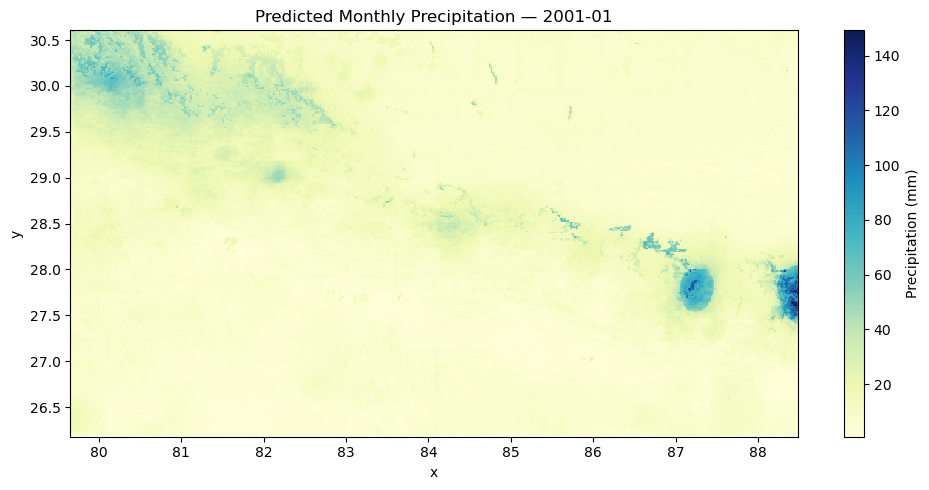

In [5]:
# ── Quick sanity check on one saved raster ───────────────────────────────────

import matplotlib.pyplot as plt

sample_path = os.path.join(OUT_DIR, f"Predicted_Raster_{START_YEAR}_{START_MONTH:02d}.tif")

if os.path.exists(sample_path):
    sample = rxr.open_rasterio(sample_path, masked=True).squeeze("band", drop=True)

    print(f"Sample raster : {sample_path}")
    print(f"  Shape       : {sample.shape}")
    print(f"  CRS         : {sample.rio.crs}")
    print(f"  Min / Max   : {float(sample.min()):.2f} / {float(sample.max()):.2f} mm")
    print(f"  Valid pixels: {int((~sample.isnull()).sum())}")

    fig, ax = plt.subplots(figsize=(10, 5))
    sample.plot(ax=ax, cmap="YlGnBu", cbar_kwargs={"label": "Precipitation (mm)"})
    ax.set_title(f"Predicted Monthly Precipitation — {START_YEAR}-{START_MONTH:02d}")
    plt.tight_layout()
    plt.show()
else:
    print(f"Sample file not found: {sample_path}")